# Research Data Screening, Cleaning and Preparation using R and Python
### Companion notebook · Online FDP on Advanced Research Methods: Analytics, Innovation and AI

**Sivaiah Bellamkonda** · Department of Computer Science & Engineering, IIIT Kottayam

This notebook runs every code example from the session on one dataset, the **Faculty Work Engagement Survey** (`fwes_raw.csv`), in the same order as the slides. Python cells can be run. The matching R code from each slide sits in a collapsible block below the Python cell. Click **R equivalent** to open it.

> **The data are simulated for teaching.** No real respondents are involved. The problems in the file were planted on purpose, so we know in advance what each check should find.

| File | Contents |
|---|---|
| `fwes_raw.csv` | 350 responses × 32 columns, with planted problems (raw, never edited by hand) |
| `fwes_codebook.csv` | Variable names, labels, valid values and missing codes |
| `fwes_hr.csv` | HR records (department, publication count) for the merge example |
| `fwes_clean.csv` | *Written by this notebook*: the analysed sample (N = 323) |
| `cleaning_log.csv` | *Written by this notebook*: every decision, with case counts |

**What is hidden in the raw file:** 6 duplicate submissions · typing errors in age, gender, designation and Likert items · `99`, `-` and `NA` used as missing codes · messy column headers · 9 failed attention checks · 7 straight-liners who were also speeders · 5 multivariate outliers.

**Hypothesised model:** Job resources (jr) → Work engagement (we) → Intention to stay (is); Job resources → Burnout (bo, −) → Intention to stay (−).

## 0. Setup

Run this once if any library is missing (same list as slide 10):

```
pip install pandas numpy scipy matplotlib missingno scikit-learn statsmodels pingouin pyampute factor_analyzer
```

<details><summary><b>R installation</b></summary>

```r
install.packages(c("tidyverse", "janitor", "naniar", "mice", "psych", "careless", "skimr", "MVN", "car", "lavaan"))
```
</details>

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110

# Files are read from the notebook's folder; if absent, from the session's GitHub repository
from pathlib import Path
REPO = "https://raw.githubusercontent.com/sivaiah911/JAIN-FDP/main/"
def path(name):
    return name if Path(name).exists() else REPO + name

# A running log of every cleaning decision (slide 38: "log every decision")
log = []
def record(step, rule, n_affected, n_remaining, decision):
    log.append(dict(step=step, rule=rule, n_affected=int(n_affected),
                    n_remaining=int(n_remaining), decision=decision))

## 1. Foundations: tidy data (slide 7)

Tidy data has three rules: each variable is a column, each respondent is a row, and each cell holds one value. The small table below is the untidy sheet from the slide. Two variables share one column (`Gender_Age`), three answers share one cell (`Q1–Q3`), a dash stands for a missing answer, and names identify the respondents.

In [2]:
untidy = pd.DataFrame({"Name": ["Anu K", "Ravi M"],
                       "Gender_Age": ["F_34", "M_41"],
                       "Q1–Q3": ["4, 5, 3", "2, 2, -"]})
untidy

,Name,Gender_Age,Q1–Q3
0,Anu K,F_34,"4, 5, 3"
1,Ravi M,M_41,"2, 2, -"


In [3]:
tidy = pd.DataFrame({"id": [1, 2]})                       # anonymous id replaces the name
tidy[["gender", "age"]] = untidy["Gender_Age"].str.split("_", expand=True)
tidy["age"] = tidy["age"].astype(int)
answers = untidy["Q1–Q3"].str.split(",", expand=True).apply(lambda s: s.str.strip())
answers.columns = ["q1", "q2", "q3"]
tidy = pd.concat([tidy, answers.replace("-", np.nan).astype(float)], axis=1)
tidy

,id,gender,age,q1,q2,q3
0,1,F,34,4.0,5.0,3.0
1,2,M,41,2.0,2.0,NaN


<details><summary><b>R equivalent</b></summary>

```r
library(tidyverse)
tidy <- untidy |>
  mutate(id = row_number(), .before = 1) |>
  select(-Name) |>
  separate_wider_delim(Gender_Age, "_", names = c("gender", "age")) |>
  separate_wider_delim(`Q1–Q3`, ", ", names = c("q1", "q2", "q3")) |>
  mutate(across(q1:q3, ~ as.numeric(na_if(.x, "-"))), age = as.integer(age))
```
</details>

## 2. The codebook (slide 9)

Every check later in this notebook is a test of the data against this table.

In [4]:
codebook = pd.read_csv(path("fwes_codebook.csv"))
codebook

,variable,label,type,valid_values,missing_codes,notes
0,id,Respondent ID,integer,"1-350, unique",none,"Raw header is ""ID"""
1,age,Age in years,integer,22-70,blank,"Raw header is ""Age"""
2,gender,Gender,category,"F, M, Other",blank,"Raw header is ""Gender"""
3,desig,Designation,category,"AP, ASP, Prof",blank,"Raw header is "" desig"" (leading space)"
4,exp_yrs,Teaching experience (years),integer,0-45; must be <= age - 20,blank,Consistency check against age
5,jr1-jr6,Job resources items,ordinal,1-5 (SD ... SA),"blank, 99, -, NA",NaN
6,we1-we6,Work engagement items,ordinal,1-5 (SD ... SA),"blank, 99, -, NA","Raw header for we1 is ""WE1 "" (trailing space)"
7,bo1-bo6,Burnout items,ordinal,1-5 (SD ... SA),"blank, 99, -, NA",NaN
8,bo2; bo5,Reverse-worded burnout items,ordinal,1-5; recode 6 - x,"blank, 99, -, NA",Positively worded; recode before scoring
9,is1-is6,Intention to stay items,ordinal,1-5 (SD ... SA),"blank, 99, -, NA",NaN


## 3. Step 1: import and declare missing codes (slide 12)

First, a quick look at why `na_values` matters. If we read the file without declaring the missing codes, a single `-` or `NA` typed into an item column turns that whole column into text (`object`), and arithmetic on it fails.

In [5]:
naive = pd.read_csv(path("fwes_raw.csv"))
print("Columns read as text without na_values:")
print(naive.select_dtypes("object").columns.tolist())

Columns read as text without na_values:
['Gender', ' desig', 'jr2', 'is2', 'submitted']


Now the import as on the slide: declare the text missing codes, clean the headers, and convert `99` to missing **only in the 24 item columns**.

In [6]:
raw = pd.read_csv(path("fwes_raw.csv"),
                  na_values=["", "NA", "-"])
# raw = pd.read_spss("fwes.sav")          # for SPSS files (needs pyreadstat)

print("Headers as received:", raw.columns[:5].tolist(), "...", raw.columns[11:12].tolist())
raw.columns = (raw.columns
               .str.strip().str.lower())
print("Headers after cleaning:", raw.columns[:5].tolist(), "...", raw.columns[11:12].tolist())

items = raw.loc[:, "jr1":"is6"].columns
n99 = int((raw[items] == 99).sum().sum())
raw[items] = raw[items].replace(99, np.nan)
print(f"99 recoded to missing in item columns: {n99} cells")

raw["submitted"] = pd.to_datetime(raw["submitted"])
raw.shape   # (350, 32)

Headers as received: ['ID', 'Age', 'Gender', ' desig', 'exp_yrs'] ... ['WE1 ']
Headers after cleaning: ['id', 'age', 'gender', 'desig', 'exp_yrs'] ... ['we1']
99 recoded to missing in item columns: 66 cells


(350, 32)

<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
library(tidyverse)
library(janitor)
raw <- read_csv("fwes_raw.csv",
  na = c("", "NA", "-"))
# raw <- haven::read_sav("fwes.sav")
raw <- clean_names(raw)
raw <- raw |>
  mutate(across(jr1:is6,
    ~ na_if(.x, 99)))
dim(raw)  # 350 32
```
</details>

In [7]:
record("Import", "Missing codes '', 'NA', '-' at import; 99 recoded to missing in jr1-is6",
       n99, len(raw), "Set to missing")
N_RECEIVED = len(raw)

## 4. Step 2: look before you touch anything (slide 13)

Checklist: numbers read as text · impossible min or max · unexpected category labels · missing count per column · constant or empty columns · row count equal to forms received.

In [8]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 32 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   id         350 non-null    int64         
 1   age        347 non-null    float64       
 2   gender     348 non-null    str           
 3   desig      350 non-null    str           
 4   exp_yrs    350 non-null    int64         
 5   jr1        347 non-null    float64       
 6   jr2        340 non-null    float64       
 7   jr3        345 non-null    float64       
 8   jr4        342 non-null    float64       
 9   jr5        346 non-null    float64       
 10  jr6        343 non-null    float64       
 11  we1        347 non-null    float64       
 12  we2        346 non-null    float64       
 13  we3        346 non-null    float64       
 14  we4        342 non-null    float64       
 15  we5        342 non-null    float64       
 16  we6        342 non-null    float64       
 17  bo1     

In [9]:
raw.describe().T

,count,mean,min,25%,50%,75%,max,std
id,350.0,173.548571,1.0,88.25,173.5,258.75,345.0,99.615546
age,347.0,41.348703,4.0,34.0,40.0,46.0,340.0,21.475003
exp_yrs,350.0,10.728571,0.0,4.0,10.0,16.0,31.0,8.052339
jr1,347.0,3.645533,1.0,3.0,4.0,4.0,5.0,1.082441
jr2,340.0,3.720588,1.0,3.0,4.0,5.0,5.0,1.092284
jr3,345.0,3.655072,0.0,3.0,4.0,4.0,5.0,1.088996
jr4,342.0,3.733918,1.0,3.0,4.0,4.0,5.0,1.056729
jr5,346.0,3.702312,1.0,3.0,4.0,5.0,5.0,1.177492
jr6,343.0,3.798834,1.0,3.0,4.0,5.0,44.0,2.44777
we1,347.0,3.755043,1.0,3.0,4.0,4.0,6.0,0.958953


In [10]:
print(raw["gender"].value_counts(dropna=False), "\n")
print(raw["desig"].value_counts(dropna=False), "\n")
print(pd.crosstab(raw["gender"].fillna("NaN"), raw["desig"].fillna("NaN")))

gender
M         186
F         149
Other       7
female      4
NaN         2
f           2
Name: count, dtype: int64 

desig
ASP           149
AP            144
Prof           55
Asst. Prof      2
Name: count, dtype: int64 

desig   AP  ASP  Asst. Prof  Prof
gender                           
F       59   68           1    21
M       80   72           1    33
NaN      0    2           0     0
Other    2    4           0     1
f        2    0           0     0
female   1    3           0     0


In [11]:
print(raw["age"].describe())
miss = raw.isna().sum()
print("\nColumns with missing values:\n", miss[miss > 0].to_string())
print("\nConstant columns:", [c for c in raw if raw[c].nunique(dropna=True) <= 1])
print("Rows:", len(raw), "| unique ids:", raw["id"].nunique())

count    347.000000
mean      41.348703
std       21.475003
min        4.000000
25%       34.000000
50%       40.000000
75%       46.000000
max      340.000000
Name: age, dtype: float64

Columns with missing values:
 age        3
gender     2
jr1        3
jr2       10
jr3        5
jr4        8
jr5        4
jr6        7
we1        3
we2        4
we3        4
we4        8
we5        8
we6        8
bo1        3
bo2        5
bo3       11
bo4        1
bo5       10
bo6        5
is1        6
is2        7
is3        6
is4        4
is5        1
is6        5

Constant columns: []
Rows: 350 | unique ids: 345


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
glimpse(raw)
skimr::skim(raw)
raw |> count(gender, desig)
summary(raw$age)
```
</details>

**What the inspection shows:** a maximum age of 245; item maxima of 6, 7, 44 and 55 on a 1–5 scale; `female` and `f` beside `F`; `Asst. Prof` beside `AP`; and 350 rows but only 345 unique ids, so duplicates are present.

## 5. Interactive: spot the problems (slide 14)

These are the eight rows shown on the slide, taken straight from the raw file. Seven problems hide in them.

In [12]:
raw.loc[raw["id"].between(101, 108),
        ["id", "age", "gender", "exp_yrs", "we1", "we2", "bo3", "att_chk"]]

,id,age,gender,exp_yrs,we1,we2,bo3,att_chk
100,101,34.0,F,8,4.0,5.0,2.0,4
101,102,245.0,M,12,3.0,4.0,3.0,4
102,103,29.0,female,3,5.0,5.0,1.0,4
103,104,41.0,M,15,6.0,4.0,2.0,4
104,105,38.0,F,30,4.0,3.0,3.0,4
105,101,34.0,F,8,4.0,5.0,2.0,4
106,106,41.0,F,7,5.0,5.0,1.0,4
107,107,45.0,M,20,3.0,3.0,3.0,1
108,108,31.0,F,5,4.0,NaN,2.0,4


| Row | Problem |
|---|---|
| 102 | Age 245: impossible |
| 103 | `female` instead of `F` |
| 104 | we1 = 6 on a 1–5 item |
| 105 | 30 years of teaching at age 38 |
| second 101 | Exact duplicate of ID 101 |
| 107 | Failed attention check (answered 1, not 4) |
| 108 | we2 missing |

## 6. Range, code and consistency checks (slide 15)

Rule from the slide: **correct a value only when you can verify it against the source; otherwise set it to missing and log it.** For this simulated file there is no paper source, so impossible values are set to missing.

In [13]:
raw["gender"].value_counts(dropna=False)

gender
M         186
F         149
Other       7
female      4
NaN         2
f           2
Name: count, dtype: int64

In [14]:
it = raw.loc[:, "jr1":"is6"]
bad = raw[((it < 1) | (it > 5)).any(axis=1)]
print("Rows with an out-of-range item value:", len(bad))
bad_cells = it[(it < 1) | (it > 5)].stack().dropna()
bad_cells.rename("value").reset_index().rename(columns={"level_0": "row", "level_1": "item"}).assign(id=lambda d: raw.loc[d["row"], "id"].to_numpy())

Rows with an out-of-range item value: 6


,row,item,value,id
0,12,jr6,44.0,13
1,14,is4,55.0,15
2,103,we1,6.0,104
3,141,jr3,0.0,141
4,299,bo1,7.0,295
5,310,we5,6.0,306


In [15]:
n_gender = raw["gender"].isin(["female", "f"]).sum()
raw["gender"] = raw["gender"].replace(
    {"female": "F", "f": "F"})

# The codebook range for age is 22-70. The slide shows only the upper bound (age > 70);
# here both bounds are used so that typing errors such as 4 or 5 are also caught.
age_bad = (raw["age"] > 70) | (raw["age"] < 22)
print("Ages outside 22-70:", raw.loc[age_bad, ["id", "age"]].to_dict("records"))
n_age = age_bad.sum()
raw.loc[age_bad, "age"] = np.nan

n_items = int(((it < 1) | (it > 5)).sum().sum())
raw[items] = it.where((it >= 1) & (it <= 5))

# Designation: one label outside the codebook list
n_desig = (raw["desig"] == "Asst. Prof").sum()
raw["desig"] = raw["desig"].replace({"Asst. Prof": "AP"})

print("gender:", raw["gender"].value_counts(dropna=False).to_dict())
print("desig: ", raw["desig"].value_counts(dropna=False).to_dict())

Ages outside 22-70: [{'id': 56, 'age': 4.0}, {'id': 102, 'age': 245.0}, {'id': 161, 'age': 5.0}, {'id': 178, 'age': 340.0}]
gender: {'M': 186, 'F': 155, 'Other': 7, nan: 2}
desig:  {'ASP': 149, 'AP': 146, 'Prof': 55}


Consistency check: teaching experience cannot exceed age − 20.

In [16]:
incons = raw[raw["exp_yrs"] > raw["age"] - 20]
print(incons[["id", "age", "exp_yrs"]])
n_exp = len(incons)
raw.loc[incons.index, "exp_yrs"] = np.nan   # cannot tell which of the two is wrong

      id   age  exp_yrs
37    38  27.0       15
89    90  30.0       25
104  105  38.0       30


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
raw |> count(gender)
bad <- raw |>
  filter(if_any(jr1:is6,
    ~ !(.x %in% 1:5) & !is.na(.x)))
raw <- raw |> mutate(
  gender = recode(gender,
    "female" = "F", "f" = "F"),
  age = if_else(age > 70, NA, age),
  across(jr1:is6, ~ if_else(
    .x %in% 1:5, .x, NA)))
raw |> filter(exp_yrs > age - 20)
```
</details>

In [17]:
record("Range/code", "gender 'female'/'f' -> 'F'", n_gender, len(raw), "Recoded")
record("Range/code", "desig 'Asst. Prof' -> 'AP'", n_desig, len(raw), "Recoded")
record("Range/code", "age outside 22-70", n_age, len(raw), "Set to missing")
record("Range/code", "Likert item outside 1-5", n_items, len(raw), "Set to missing")
record("Consistency", "exp_yrs > age - 20", n_exp, len(raw), "exp_yrs set to missing")

## 7. Finding and removing duplicates (slide 16)

Three kinds: **exact copies** (every column identical), **same ID with different answers** (entry slip or resubmission), and **same answers under a new ID** (the same person submitting twice online).

In [18]:
# Same ID appearing more than once
raw[raw.duplicated("id", keep=False)].sort_values(["id", "submitted"])[
    ["id", "age", "gender", "jr1", "jr2", "we3", "bo1", "duration", "submitted"]]

,id,age,gender,jr1,jr2,we3,bo1,duration,submitted
100,101,34.0,F,3.0,2.0,2.0,4.0,732,2026-08-10 10:23:30
105,101,34.0,F,3.0,2.0,2.0,4.0,732,2026-08-10 10:23:30
155,155,25.0,M,5.0,4.0,4.0,2.0,290,2026-08-15 10:56:36
240,155,25.0,M,4.0,4.0,4.0,2.0,430,2026-08-16 11:56:36
207,206,30.0,F,3.0,2.0,4.0,3.0,432,2026-08-18 10:26:03
274,206,30.0,F,3.0,2.0,4.0,3.0,432,2026-08-18 10:26:03
256,254,37.0,M,3.0,3.0,3.0,4.0,243,2026-08-21 04:21:08
321,254,37.0,M,3.0,3.0,3.0,4.0,553,2026-08-23 01:21:08
185,341,36.0,F,4.0,4.0,5.0,4.0,448,2026-08-27 04:25:12
346,341,36.0,F,4.0,4.0,5.0,4.0,448,2026-08-27 04:25:12


In [19]:
# Same answers, ignoring id and timestamp
cols = raw.columns.drop(["id", "submitted"])
raw[raw.duplicated(cols, keep=False)].sort_values(list(cols[:6]))[
    ["id", "age", "gender", "desig", "jr1", "we2", "is6", "submitted"]]

,id,age,gender,desig,jr1,we2,is6,submitted
253,251,25.0,M,AP,4.0,4.0,4.0,2026-08-21 01:56:22
262,345,25.0,M,AP,4.0,4.0,4.0,2026-08-21 02:31:22
207,206,30.0,F,AP,3.0,4.0,3.0,2026-08-18 10:26:03
274,206,30.0,F,AP,3.0,4.0,3.0,2026-08-18 10:26:03
100,101,34.0,F,AP,3.0,5.0,2.0,2026-08-10 10:23:30
105,101,34.0,F,AP,3.0,5.0,2.0,2026-08-10 10:23:30
185,341,36.0,F,AP,4.0,4.0,4.0,2026-08-27 04:25:12
346,341,36.0,F,AP,4.0,4.0,4.0,2026-08-27 04:25:12


Keep the earliest submission for each ID, then drop any remaining row whose answers repeat another respondent's.

In [20]:
n0 = len(raw)
raw = (raw.sort_values("submitted")
       .drop_duplicates("id"))
n_id = n0 - len(raw)

cols = raw.columns.drop(["id", "submitted"])
n1 = len(raw)
raw = raw[~raw.duplicated(cols)]
n_content = n1 - len(raw)

print(f"Removed {n_id} duplicate IDs and {n_content} same-answers/new-ID row(s): {len(raw)} remain")
record("Duplicates", "Same id (keep earliest) or identical answers under a new id",
       n0 - len(raw), len(raw), "Excluded")
N_AFTER_DUP = len(raw)

Removed 5 duplicate IDs and 1 same-answers/new-ID row(s): 344 remain


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
raw |> get_dupes(id)
raw |> get_dupes(-c(id, submitted))
raw <- raw |> arrange(submitted) |>
  distinct(id, .keep_all = TRUE)
# then remove the same-answers / new-id copy
raw <- raw |> distinct(across(-c(id, submitted)), .keep_all = TRUE)
```
</details>

## 8. Careless responding (slides 17–18)

Four indicators: **attention check**, **long-string** (longest run of identical answers), **response time** (under about 2 seconds per item), and **intra-individual response variability** (IRV, the row standard deviation). Combine at least two indicators, and use a rule you can state in the paper.

pandas has no `careless` package, so `longstring` is a three-line function.

In [21]:
it = raw.loc[:, "jr1":"is6"]

def longstring(row):
    runs = (row != row.shift()).cumsum()
    return runs.value_counts().max()

raw["ls"] = it.apply(longstring, axis=1)
raw["irv"] = it.std(axis=1)
raw["fast"] = raw["duration"] < 2 * 24          # under 2 s per item
raw["att_fail"] = raw["att_chk"] != 4

pd.crosstab(raw["att_fail"], raw["fast"], margins=True)

fast,False,True,All
att_fail,,,
False,325,10,335
True,9,0,9
All,334,10,344


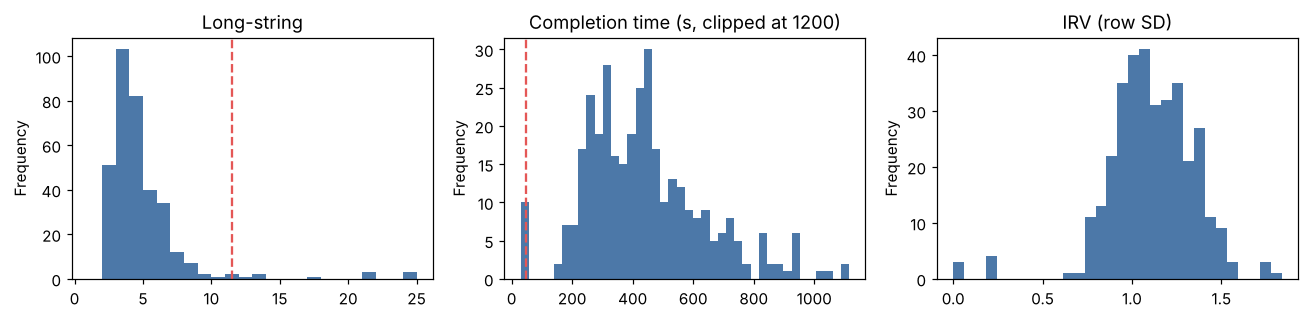

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
raw["ls"].plot.hist(bins=range(1, 26), ax=ax[0], color="#4C78A8", title="Long-string")
ax[0].axvline(11.5, color="#E45756", ls="--")
raw["duration"].clip(upper=1200).plot.hist(bins=40, ax=ax[1], color="#4C78A8",
                                            title="Completion time (s, clipped at 1200)")
ax[1].axvline(48, color="#E45756", ls="--")
raw["irv"].plot.hist(bins=30, ax=ax[2], color="#4C78A8", title="IRV (row SD)")
plt.tight_layout(); plt.show()

In [23]:
flag = raw[raw["att_fail"]
           | ((raw["ls"] >= 12) & raw["fast"])]
print("Flagged:", len(flag))
flag[["id", "att_chk", "ls", "irv", "duration", "fast", "att_fail"]].sort_values("att_fail", ascending=False)

Flagged: 16


,id,att_chk,ls,irv,duration,fast,att_fail
81,82,3,5,1.153916,448,False,True
107,107,1,3,1.041703,828,False,True
115,115,1,3,1.498187,320,False,True
129,129,5,2,1.350657,329,False,True
223,222,2,4,1.032094,448,False,True
228,227,2,5,0.775532,432,False,True
246,244,1,2,1.390965,574,False,True
252,250,3,4,1.587428,289,False,True
311,307,3,3,1.334465,569,False,True
68,69,4,21,0.204124,40,True,False


Note who is **not** flagged: a few respondents are fast but give varied answers, and a few have a long run of identical answers but took a normal time. One indicator alone is not enough to exclude them.

In [24]:
raw.loc[(raw["fast"] ^ (raw["ls"] >= 12)) & ~raw["att_fail"],
        ["id", "ls", "irv", "duration", "fast"]]

,id,ls,irv,duration,fast
17,18,13,0.931533,287,False
30,31,4,1.444003,37,True
106,106,12,1.434563,628,False
118,118,6,1.241572,38,True
134,134,3,0.824226,37,True
212,211,13,0.991814,363,False


In [25]:
n_att = int(raw["att_fail"].sum())
raw = raw[~raw["att_fail"]]
record("Careless", "Failed instructed-response item (att_chk != 4)", n_att, len(raw), "Excluded")
N_AFTER_ATT = len(raw)

sl = (raw["ls"] >= 12) & raw["fast"]
n_sl = int(sl.sum())
raw = raw[~sl]
record("Careless", "Long-string >= 12 AND under 2 s per item", n_sl, len(raw), "Excluded")
N_AFTER_CARELESS = len(raw)
print(f"{n_att} failed the attention check, {n_sl} were straight-liners and speeders: {len(raw)} remain")

9 failed the attention check, 7 were straight-liners and speeders: 328 remain


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
library(careless)
it <- raw |> select(jr1:is6)
raw <- raw |> mutate(
  ls   = longstring(it),
  irv  = irv(it),
  fast = duration < 2 * ncol(it),
  att_fail = att_chk != 4)
raw |> count(att_fail, fast)
flag <- raw |> filter(att_fail |
  (ls >= 12 & fast))
raw <- raw |> filter(!att_fail, !(ls >= 12 & fast))
```
</details>

## 9. Missing data: mechanisms and quiz (slides 19–20)

| Mechanism | Meaning | Consequence |
|---|---|---|
| **MCAR** | Unrelated to any variable, observed or not | Deletion unbiased, but power lost |
| **MAR** | Depends on variables you have observed | Multiple imputation and FIML unbiased |
| **MNAR** | Depends on the missing value itself | No method fully fixes it: sensitivity analysis |

Quiz answers: Scenario 1 (lower incomes skip income) = **MNAR**; Scenario 2 (women skip overtime, gender recorded) = **MAR**; Scenario 3 (server error, random 5%) = **MCAR**.

## 10. Diagnose: how much, where, and what pattern (slide 21)

In [26]:
it = raw.loc[:, "jr1":"is6"]
(raw.isna().mean() * 100).round(2).sort_values(ascending=False).head(15)

bo3    3.05
bo5    3.05
jr2    3.05
jr6    2.44
we5    2.44
we6    2.44
jr4    2.44
age    2.13
is2    2.13
we4    2.13
is1    1.83
is3    1.83
jr3    1.83
bo2    1.52
bo6    1.52
dtype: float64

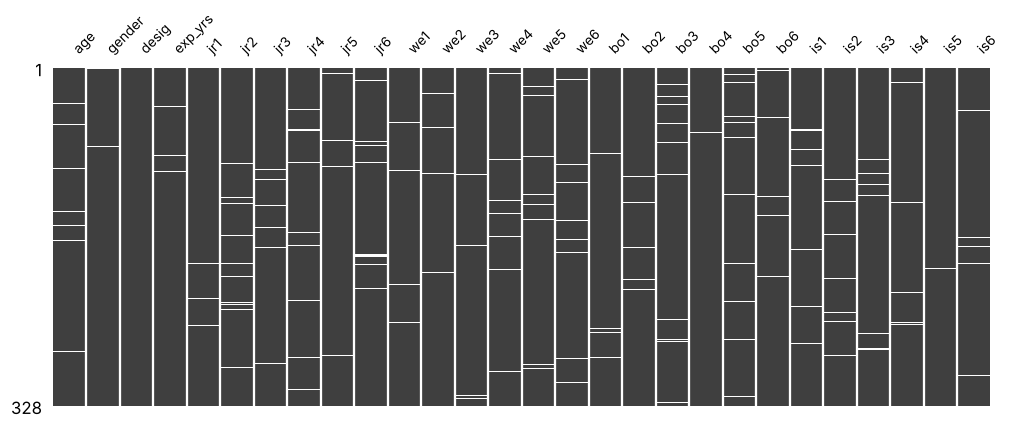

In [27]:
import missingno as msno
msno.matrix(raw.loc[:, "age":"is6"], figsize=(11, 4), fontsize=9, sparkline=False)
plt.show()

In [28]:
# Little's MCAR test, as on the slide (pyampute returns the p-value only)
from pyampute.exploration import mcar_statistical_tests as mst
p_little = mst.MCARTest(method="little").little_mcar_test(it)
print(f"Little's MCAR test (pyampute): p = {p_little:.3f}")

Little's MCAR test (pyampute): p = 0.418


For the methods section we also need χ² and df, so here is the same statistic written out (it follows pyampute's calculation).

In [29]:
def little_mcar(X):
    X = X.copy()
    mu, S = X.mean(), X.cov()
    pattern = X.isna().apply(lambda r: tuple(r), axis=1)
    d2, pj = 0.0, 0
    for _, grp in X.groupby(pattern):
        obs = grp.columns[~grp.isna().any()]
        pj += len(obs)
        diff = (grp[obs].mean() - mu[obs]).to_numpy()
        d2 += len(grp) * diff @ np.linalg.solve(S.loc[obs, obs], diff)
    df = pj - X.shape[1]
    return d2, df, stats.chi2.sf(d2, df)

chi2_l, df_l, p_l = little_mcar(it)
print(f"Little's MCAR test: chi2 = {chi2_l:.1f}, df = {df_l}, p = {p_l:.3f}  (N = {len(it)})")

Little's MCAR test: chi2 = 976.5, df = 968, p = 0.418  (N = 328)


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
library(naniar)
miss_var_summary(raw)    # % missing per item
vis_miss(raw)
mcar_test(select(raw, jr1:is6))
```
</details>

*R's `naniar::mcar_test` uses EM (maximum likelihood) estimates of the means and covariances, so its χ² will differ slightly from the Python value above.*

## 11. Seven ways to handle missing values (slides 22–23)

A short demonstration of why **mean substitution shrinks variance** while person-mean and multiple imputation do less damage.

In [30]:
demo = pd.DataFrame({"observed (listwise)": it.var()})
demo["mean substitution"] = it.fillna(it.mean()).var()
# person mean: own mean on the same scale (for one item missing in a long scale)
pm = it.copy()
for c in ["jr", "we", "bo", "is"]:
    block = [f"{c}{i}" for i in range(1, 7)]
    pm[block] = pm[block].apply(lambda col: col.fillna(pm[block].mean(axis=1)))
demo["person mean"] = pm.var()
demo = demo.round(3)
demo.loc[demo["observed (listwise)"].sub(demo["mean substitution"]).sort_values(ascending=False).index[:6]]

,observed (listwise),mean substitution,person mean
bo3,1.304,1.264,1.268
bo5,1.254,1.216,1.247
jr2,1.184,1.148,1.163
jr6,1.240,1.210,1.224
we6,1.157,1.128,1.141
jr4,1.111,1.084,1.106


In [31]:
print("Listwise deletion would keep", len(it.dropna()), "of", len(it), "cases",
      f"({1 - len(it.dropna()) / len(it):.1%} lost)")

Listwise deletion would keep 210 of 328 cases (36.0% lost)


Even though no item has more than about 3% missing, the blanks fall on different respondents, so listwise deletion would discard about a third of the sample. This is why MI or FIML is preferred.

**Decision guide (slide 23):** most of the questionnaire blank → remove and report · one item missing in a multi-item scale → person mean, or leave to MI/FIML · under 5% and Little's test not significant → listwise defensible, MI or FIML preferred · more missing or MAR plausible → MI (mice) or FIML (lavaan, AMOS) · MNAR suspected → sensitivity analysis and state the limitation.

## 12. Multiple imputation and FIML (slide 24)

Python: `IterativeImputer` with `sample_posterior=True`, 20 times with different seeds, then pool with **Rubin's rules**. The analysis model is the one on the slide, `we1 ~ jr1 + jr2`. Gender and designation are added as auxiliary variables.

In [32]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
import statsmodels.api as sm

it = raw.loc[:, "jr1":"is6"]
aux = pd.get_dummies(raw[["gender", "desig"]], drop_first=True, dtype=float)
X_imp = pd.concat([it, aux], axis=1)

imps = []
for m in range(20):
    ii = IterativeImputer(sample_posterior=True, random_state=m,
                          min_value=1, max_value=5, max_iter=10)
    done = pd.DataFrame(ii.fit_transform(X_imp), columns=X_imp.columns, index=X_imp.index)
    imps.append(done[it.columns])

# Analyse each completed dataset
est, var = [], []
for d in imps:
    fit = sm.OLS(d["we1"], sm.add_constant(d[["jr1", "jr2"]])).fit()
    est.append(fit.params); var.append(fit.bse ** 2)
est, var = pd.DataFrame(est), pd.DataFrame(var)

# Rubin's rules
m = len(imps)
qbar = est.mean()                    # pooled estimate
ubar = var.mean()                    # within-imputation variance
b = est.var(ddof=1)                  # between-imputation variance
t = ubar + (1 + 1 / m) * b           # total variance
pooled = pd.DataFrame({"estimate": qbar, "se": np.sqrt(t),
                       "fmi": ((1 + 1 / m) * b / t)}).round(4)
pooled

,estimate,se,fmi
const,2.5531,0.1978,0.0117
jr1,0.1749,0.0564,0.0300
jr2,0.1500,0.0570,0.0284


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
library(mice)
it  <- raw |> select(jr1:is6)
imp <- mice(it, m = 20,
  method = "pmm", seed = 2026)
plot(imp)       # convergence
densityplot(imp)
fit <- with(imp, lm(we1 ~ jr1 + jr2))
summary(pool(fit))
# CFA or SEM: use FIML instead
cfa(model, raw, missing = "fiml")
```
</details>

*FIML is run inside the CFA/SEM software (lavaan `missing = "fiml"`, AMOS, Mplus), so it has no separate Python step here. The working file keeps its missing values for that reason.*

## 13. Reverse-coding negatively worded items (slide 34)

This step must come **before** composites and outlier checks. `bo2` and `bo5` are positively worded inside the burnout scale. New value = (max + min) − x = 6 − x. Recode once, into new columns.

In [33]:
it = raw.loc[:, "jr1":"is6"]
print("Before: correlation of bo2, bo5 with the rest of the burnout scale")
print(it[["bo1", "bo3", "bo4", "bo6"]].mean(axis=1).pipe(
      lambda s: it[["bo2", "bo5"]].corrwith(s)).round(2))

for c in ["bo2", "bo5"]:
    raw[c + "_r"] = 6 - raw[c]

print("\nAfter recoding:")
print(raw[["bo1", "bo3", "bo4", "bo6"]].mean(axis=1).pipe(
      lambda s: raw[["bo2_r", "bo5_r"]].corrwith(s)).round(2))
print("\nCheck mapping:", pd.crosstab(raw["bo2"], raw["bo2_r"]).to_dict())

Before: correlation of bo2, bo5 with the rest of the burnout scale
bo2   -0.66
bo5   -0.63
dtype: float64

After recoding:
bo2_r    0.66
bo5_r    0.63
dtype: float64

Check mapping: {1.0: {1.0: 0, 2.0: 0, 3.0: 0, 4.0: 0, 5.0: 61}, 2.0: {1.0: 0, 2.0: 0, 3.0: 0, 4.0: 98, 5.0: 0}, 3.0: {1.0: 0, 2.0: 0, 3.0: 92, 4.0: 0, 5.0: 0}, 4.0: {1.0: 0, 2.0: 53, 3.0: 0, 4.0: 0, 5.0: 0}, 5.0: {1.0: 19, 2.0: 0, 3.0: 0, 4.0: 0, 5.0: 0}}


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
raw <- raw |> mutate(across(
  c(bo2, bo5), ~ 6 - .x,
  .names = "{.col}_r"))
```
</details>

## 14. Composite scores (slide 35, used for outlier checks)

Average the six items of each construct, using `bo2_r` and `bo5_r` in place of the originals, and set the composite to missing when fewer than 5 of 6 items were answered.

> **Caution about the slide code:** after reverse-coding, `raw.filter(regex="^bo[1-6]$")` in Python and `pick(bo1:bo6)` in R still pick up the **original** bo2 and bo5. List the items explicitly, as below.

In [34]:
scales = {"jr": [f"jr{i}" for i in range(1, 7)],
          "we": [f"we{i}" for i in range(1, 7)],
          "bo": ["bo1", "bo2_r", "bo3", "bo4", "bo5_r", "bo6"],
          "is": [f"is{i}" for i in range(1, 7)]}

def composite(df, cols, min_items=5):
    return df[cols].mean(axis=1).where(df[cols].notna().sum(axis=1) >= min_items)

for k, cols in scales.items():
    raw[k] = composite(raw, cols)

comp = raw.set_index("id")[list(scales)].dropna()
print(len(comp), "cases with all four composites")
comp.describe().round(2)

325 cases with all four composites


,jr,we,bo,is
count,325.00,325.00,325.00,325.00
mean,3.71,3.75,2.41,3.68
std,0.86,0.79,0.87,0.84
min,1.00,1.00,1.00,1.00
25%,3.17,3.33,1.67,3.17
50%,3.83,3.83,2.33,3.83
75%,4.33,4.33,3.00,4.33
max,5.00,5.00,5.00,5.00


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
# after reverse-coding bo2, bo5
comp <- raw |> transmute(
  id,
  jr = rowMeans(pick(jr1:jr6)),
  we = rowMeans(pick(we1:we6)),
  bo = rowMeans(pick(bo1, bo2_r, bo3, bo4, bo5_r, bo6)),
  is = rowMeans(pick(is1:is6))) |>
  drop_na()
```
</details>

## 15. Univariate outliers (slides 25 and 27)

Two rules: |z| > 3.29 (p < .001, two-tailed; Tabachnick and Fidell, 2019) and Tukey's boxplot rule (beyond 1.5 × IQR). Use them on continuous variables and composites, not on single 1–5 items.

In [35]:
z = stats.zscore(comp)
print("Composites with |z| > 3.29:")
print(comp[(np.abs(z) > 3.29).any(axis=1)].round(2))

def tukey(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
print("\nBeyond 1.5 x IQR:", {c: int(tukey(comp[c]).sum()) for c in comp})
print("Age, experience, duration beyond 1.5 x IQR:",
      {c: int(tukey(raw[c].dropna()).sum()) for c in ["age", "exp_yrs", "duration"]})

Composites with |z| > 3.29:
      jr   we    bo    is
id                       
40  2.67  1.0  4.33  1.67

Beyond 1.5 x IQR: {'jr': 6, 'we': 10, 'bo': 0, 'is': 3}
Age, experience, duration beyond 1.5 x IQR: {'age': 0, 'exp_yrs': 0, 'duration': 11}


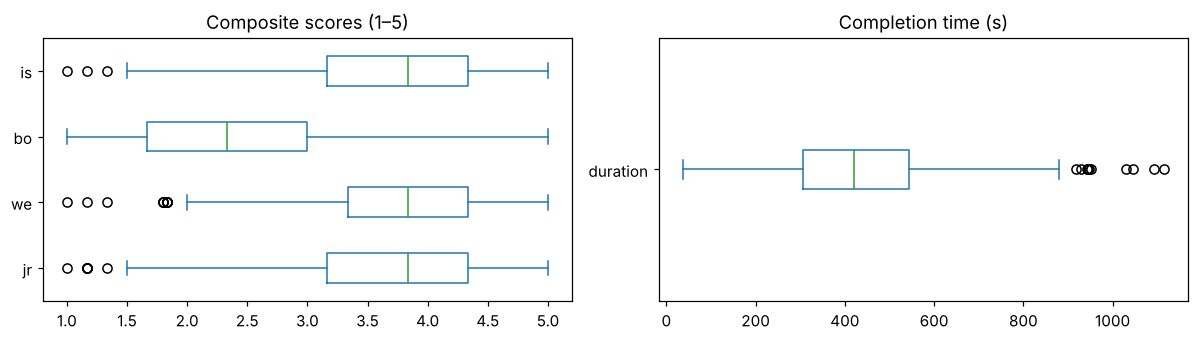

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
comp.plot.box(ax=ax[0], vert=False, title="Composite scores (1–5)")
raw["duration"].plot.box(ax=ax[1], vert=False, title="Completion time (s)")
plt.tight_layout(); plt.show()

<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
z <- scale(select(comp, -id))
which(abs(z) > 3.29, arr.ind = TRUE)
boxplot(select(comp, -id), horizontal = TRUE)
```
</details>

## 16. Multivariate outliers: Mahalanobis D² (slides 26–27)

D² is the distance of a case from the centre of all four composites together, allowing for their correlations. Compare with χ² at p < .001, df = number of variables: χ²(4) = 18.47.

In [37]:
d = (comp - comp.mean()).to_numpy()
inv = np.linalg.inv(np.cov(d.T))
d2 = ((d @ inv) * d).sum(axis=1)
cut = stats.chi2.ppf(.999, 4)
comp["d2"] = d2
print(f"Cut-off chi2(4) at p < .001 = {cut:.2f}")
mv_out = comp[comp["d2"] > cut].sort_values("d2", ascending=False)
mv_out.round(2)

Cut-off chi2(4) at p < .001 = 18.47


,jr,we,bo,is,d2
id,,,,,
2,1.17,4.83,1.17,1.00,36.50
159,1.17,1.17,1.17,4.67,35.05
197,4.83,4.83,4.83,1.33,30.56
27,5.00,1.33,1.50,4.50,30.52
214,2.83,5.00,4.83,4.67,28.55


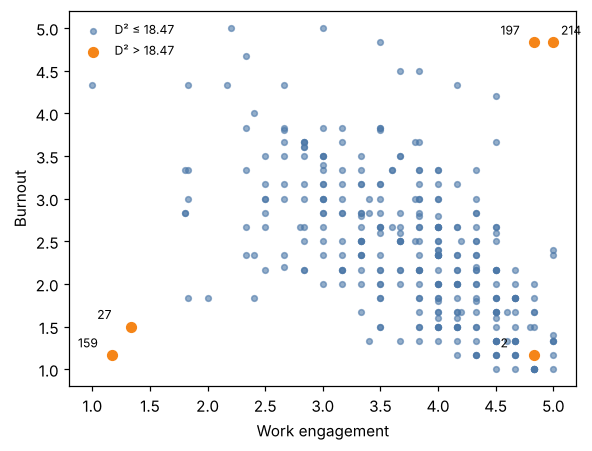

In [38]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ok = comp["d2"] <= cut
ax.scatter(comp.loc[ok, "we"], comp.loc[ok, "bo"], s=14, color="#4C78A8", alpha=.6, label="D² ≤ 18.47")
ax.scatter(comp.loc[~ok, "we"], comp.loc[~ok, "bo"], s=40, color="#F58518", label="D² > 18.47")
for k, i in enumerate(mv_out.index):
    ax.annotate(str(i), (comp.loc[i, "we"], comp.loc[i, "bo"]), xytext=(-22 if comp.loc[i, "we"] < 4.9 else 5, 5),
                textcoords="offset points", fontsize=8)
ax.set_xlabel("Work engagement"); ax.set_ylabel("Burnout"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
d2 <- mahalanobis(select(comp, -id),
  colMeans(select(comp, -id)), cov(select(comp, -id)))
comp$id[d2 > qchisq(.999, df = 4)]
```
</details>

## 17. Interactive: what would you do with respondent 214? (slide 28)

No entry error, attention check passed, normal completion time, but engagement and burnout are both very high. If the case is genuine, the answer is **D: analyse both ways** and report both.

In [39]:
print(raw.loc[raw["id"] == 214, ["id", "age", "gender", "desig", "att_chk", "duration", "ls", "jr", "we", "bo", "is"]].round(2).to_string(index=False))
print(f"\nD2 for 214 = {comp.loc[214, 'd2']:.1f}  (cut-off {cut:.2f})")

 id  age gender desig  att_chk  duration  ls   jr  we   bo   is
214 25.0      M    AP        4       603   7 2.83 5.0 4.83 4.67

D2 for 214 = 28.6  (cut-off 18.47)


In [40]:
c4 = list(scales)
with_out = comp[c4].corr()
without = comp.loc[comp["d2"] <= cut, c4].corr()
both = pd.concat({"with outliers": with_out.round(2), "without": without.round(2),
                  "difference": (with_out - without).round(3)}, axis=1)
both

with outliers                   without                   difference                     
              jr    we    bo    is      jr    we    bo    is         jr     we     bo     is
jr          1.00  0.50 -0.35  0.44    1.00  0.54 -0.40  0.46      0.000 -0.037  0.050 -0.024
we          0.50  1.00 -0.53  0.47    0.54  1.00 -0.61  0.55     -0.037  0.000  0.088 -0.082
bo         -0.35 -0.53  1.00 -0.47   -0.40 -0.61  1.00 -0.49      0.050  0.088  0.000  0.024
is          0.44  0.47 -0.47  1.00    0.46  0.55 -0.49  1.00     -0.024 -0.082  0.024  0.000

The correlations barely move when the five cases are removed, so the substantive results are the same either way. As on slide 39, the five cases are excluded after review, and the paper reports both analyses.

In [41]:
n_mv = len(mv_out)
raw = raw[~raw["id"].isin(mv_out.index)]
record("Outliers", f"Mahalanobis D2 > chi2(4) = {cut:.2f}, p < .001 (reviewed case by case)",
       n_mv, len(raw), "Excluded; results compared with and without")
N_FINAL = len(raw)
comp = comp.loc[comp["d2"] <= cut, c4]
print(N_FINAL, "cases in the analysed sample")

323 cases in the analysed sample


## 18. Normality: skewness, kurtosis and Mardia (slides 29–30)

Workable for ML: |skew| < 2 and |kurtosis| < 7 (West, Finch and Curran, 1995); severe beyond 3 and 10 (Kline, 2016). pandas reports **excess** kurtosis (normal = 0).

In [42]:
it = raw.loc[:, "jr1":"is6"]
sk = it.agg(["mean", "std", "skew", "kurt"]).T.round(2)
sk["flag"] = np.where((sk["skew"].abs() >= 2) | (sk["kurt"].abs() >= 7), "check", "")
print(f"Skewness range {sk['skew'].min()} to {sk['skew'].max()}; kurtosis range {sk['kurt'].min()} to {sk['kurt'].max()}")
sk

Skewness range -0.82 to 2.72; kurtosis range -0.93 to 7.47


,mean,std,skew,kurt,flag
jr1,3.68,1.07,-0.64,-0.23,
jr2,3.75,1.07,-0.73,-0.05,
jr3,3.68,1.06,-0.52,-0.36,
jr4,3.75,1.03,-0.76,0.19,
jr5,3.73,1.15,-0.82,-0.03,
jr6,3.72,1.10,-0.78,0.10,
we1,3.77,0.92,-0.50,-0.19,
we2,3.82,1.01,-0.76,0.08,
we3,3.74,1.06,-0.74,-0.10,
we4,3.80,0.97,-0.81,0.31,


In [43]:
def mardia(X):
    X = np.asarray(X, float); n, p = X.shape
    Xc = X - X.mean(0)
    S = np.cov(Xc.T, bias=True)
    D = Xc @ np.linalg.inv(S) @ Xc.T
    b1 = (D ** 3).sum() / n ** 2
    b2 = (np.diag(D) ** 2).mean()
    skew_stat = n * b1 / 6
    df = p * (p + 1) * (p + 2) / 6
    kurt_z = (b2 - p * (p + 2)) / np.sqrt(8 * p * (p + 2) / n)
    return pd.Series({"b1p (skewness)": b1, "chi2": skew_stat, "df": df,
                      "p_skew": stats.chi2.sf(skew_stat, df),
                      "b2p (kurtosis)": b2, "z": kurt_z,
                      "p_kurt": 2 * stats.norm.sf(abs(kurt_z))})

print("Mardia's test on complete cases (n =", len(it.dropna()), "; Mardia needs complete rows)")
mardia(it.dropna()).round(4)

Mardia's test on complete cases (n = 205 ; Mardia needs complete rows)


b1p (skewness)      96.3439
chi2              3291.7515
df                2600.0000
p_skew               0.0000
b2p (kurtosis)     656.5612
z                    6.5984
p_kurt               0.0000
dtype: float64

In [44]:
import pingouin as pg
# pingouin offers the Henze-Zirkler test (not Mardia); the conclusion is the same
pg.multivariate_normality(it.dropna(), alpha=.05)

HZResults(hz=np.float64(1.0040719774832105), pval=np.float64(2.1167821811427424e-155), normal=False)

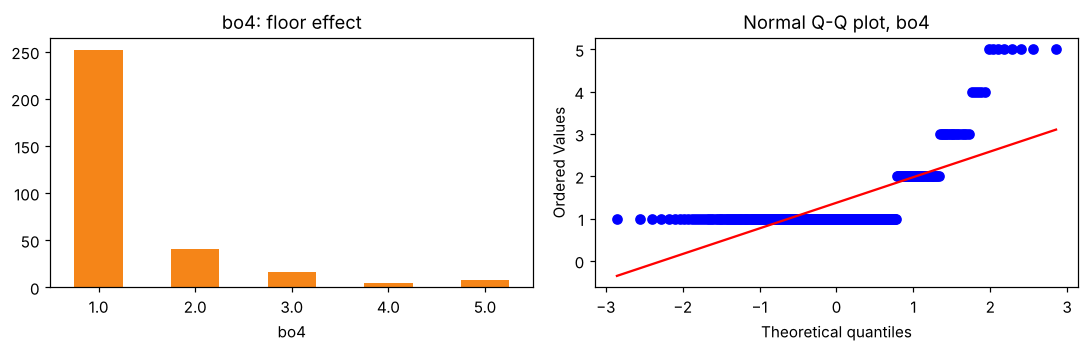

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
it["bo4"].value_counts().sort_index().plot.bar(ax=ax[0], color="#F58518", rot=0, title="bo4: floor effect")
stats.probplot(it["bo4"].dropna(), plot=ax[1]); ax[1].set_title("Normal Q-Q plot, bo4")
plt.tight_layout(); plt.show()

<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
library(psych)
it <- raw |> select(jr1:is6)
describe(it)[, c("mean", "sd",
  "skew", "kurtosis")]
mardia(it)
hist(raw$bo4)
qqnorm(raw$bo4); qqline(raw$bo4)
# if violated, in lavaan:
cfa(model, raw, estimator = "MLR")
```
</details>

**Reviewer reading (slide 33):** `bo4` exceeds both cut-offs (check the wording and the floor effect); Mardia is significant, so the CFA should be estimated with MLR in lavaan or Bollen–Stine bootstrapping in AMOS.

## 19. Linearity and multicollinearity (slide 31)

Correlations above .85–.90 between constructs suggest redundancy. VIF above 5 is a concern (some use 10). Full-collinearity VIF above 3.3 also flags method bias (Kock, 2015).

In [46]:
comp.corr().round(2)

,jr,we,bo,is
jr,1.00,0.54,-0.40,0.46
we,0.54,1.00,-0.61,0.55
bo,-0.40,-0.61,1.00,-0.49
is,0.46,0.55,-0.49,1.00


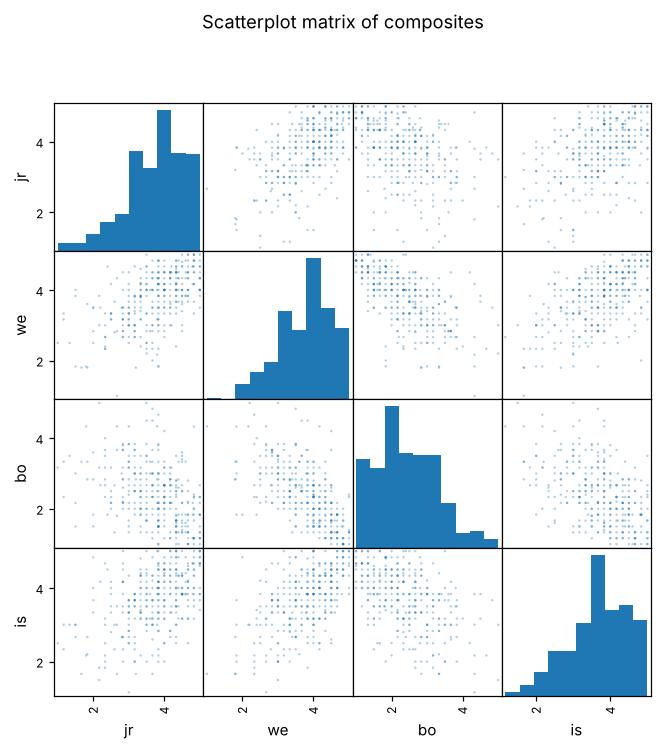

In [47]:
pd.plotting.scatter_matrix(comp, figsize=(7, 7), alpha=.35, diagonal="hist", s=10)
plt.suptitle("Scatterplot matrix of composites", y=1.0); plt.show()

In [48]:
# VIF for the predictors of intention to stay: diagonal of the inverse correlation matrix
X = comp[["jr", "we", "bo"]]
print("VIF (is ~ jr + we + bo):", dict(zip(X.columns, np.diag(np.linalg.inv(X.corr())).round(2))))

# Full-collinearity VIF: every construct against all the others (Kock, 2015)
print("Full-collinearity VIF:   ", dict(zip(comp.columns, np.diag(np.linalg.inv(comp.corr())).round(2))))

VIF (is ~ jr + we + bo): {'jr': np.float64(1.43), 'we': np.float64(1.93), 'bo': np.float64(1.62)}
Full-collinearity VIF:    {'jr': np.float64(1.5), 'we': np.float64(2.07), 'bo': np.float64(1.7), 'is': np.float64(1.6)}


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
cor(comp); pairs(comp)
car::vif(lm(is ~ jr + we + bo, comp))
```
</details>

## 20. Common method bias: Harman's single-factor test (slide 32)

Put all 24 items into one unrotated factor. More than 50% of variance on that factor suggests method bias. Harman's test is weak, so treat it as a first look only.

> **Note:** `factor_analyzer` 0.5.1 calls a scikit-learn argument (`force_all_finite`) that was renamed in scikit-learn 1.6. If you see `TypeError: check_array() got an unexpected keyword argument 'force_all_finite'`, the small patch below fixes it.

In [49]:
from factor_analyzer import FactorAnalyzer
import factor_analyzer.factor_analyzer as _fa_mod
import sklearn.utils.validation as _skv

try:                                            # patch only if this scikit-learn needs it
    _skv.check_array(np.ones((2, 2)), force_all_finite=True)
except TypeError:
    _orig = _skv.check_array
    def _check_array(*a, force_all_finite=None, **k):
        if force_all_finite is not None:
            k["ensure_all_finite"] = force_all_finite
        return _orig(*a, **k)
    _fa_mod.check_array = _check_array

it = raw[[c for c in raw.loc[:, "jr1":"is6"].columns]]   # original items, as on the slide
fa = FactorAnalyzer(1, rotation=None)
fa.fit(it.dropna())
var_1f = fa.get_factor_variance()[1][0]
print(f"Single unrotated factor explains {var_1f:.1%} of the variance (threshold 50%)")

ev = np.linalg.eigvalsh(it.dropna().corr())[::-1]
print(f"First principal component (as in SPSS 'unrotated PCA'): {ev[0] / len(ev):.1%}")

Single unrotated factor explains 33.3% of the variance (threshold 50%)
First principal component (as in SPSS 'unrotated PCA'): 36.0%


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
psych::fa(it, nfactors = 1,
    rotate = "none")$Vaccounted
```
</details>

## 21. Composites, recoding, dummies, standardising (slide 35)

In [50]:
# Composite: rowMeans with na.rm, plus the 5-of-6 rule from Section 14
we_it = raw[scales["we"]]
we = we_it.mean(axis=1)
print("we composite (first 5):", we.head().round(2).tolist())

# Recoding into bands
raw["exp_band"] = pd.cut(raw.exp_yrs, [0, 5, 15, np.inf], include_lowest=True,
                         labels=["0-5", "6-15", "16+"])
print(raw["exp_band"].value_counts(dropna=False).to_dict())

we composite (first 5): [3.17, 4.33, 4.17, 4.5, 1.8]
{'6-15': 128, '0-5': 103, '16+': 89, nan: 3}


In [51]:
# Dummy coding: k categories -> k - 1 indicators plus a reference group (AP)
pd.get_dummies(raw.desig, drop_first=True, dtype=int).head()

,ASP,Prof
0,1,0
2,0,0
3,1,0
4,1,0
5,1,0


In [52]:
# Standardising before building interaction terms
raw["we_z"] = (raw["we"] - raw["we"].mean()) / raw["we"].std()
raw["jr_c"] = raw["jr"] - raw["jr"].mean()                # centring
raw["jr_x_we"] = raw["jr_c"] * raw["we_z"]
raw[["we", "we_z", "jr_c", "jr_x_we"]].describe().round(2).loc[["mean", "std"]]

,we,we_z,jr_c,jr_x_we
mean,3.76,0.0,-0.00,0.45
std,0.76,1.0,0.83,0.89


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
we <- rowMeans(we_it, na.rm = TRUE)
cut(raw$exp_yrs, c(0, 5, 15, Inf))
model.matrix(~ desig, raw)
raw$we_z <- scale(raw$we)
```
</details>

## 22. Reshaping and merging (slide 36)

Wide to long (for item-level plots or multilevel models), and merging HR records by a shared key. Compare row counts before and after: a duplicated key silently multiplies rows.

In [53]:
long = raw[["id"] + list(raw.loc[:, "jr1":"is6"].columns)].melt(
    id_vars="id", var_name="item", value_name="score")
print(raw.shape, "->", long.shape)
long.sort_values(["id", "item"]).head(6)

(323, 46) -> (7752, 3)


,id,item,score
3876,1,bo1,1.0
4199,1,bo2,2.0
4522,1,bo3,2.0
4845,1,bo4,1.0
5168,1,bo5,3.0
5491,1,bo6,3.0


In [54]:
hr = pd.read_csv(path("fwes_hr.csv"))
print("HR records:", hr.shape, "| unique ids:", hr["id"].is_unique)

n_before = len(raw)
merged = raw.merge(hr, on="id", how="left", validate="1:1", indicator=True)
print("Rows before/after merge:", n_before, len(merged))
print(merged["_merge"].value_counts().to_dict())

# anti-join: survey respondents with no HR record
no_hr = merged.loc[merged["_merge"] == "left_only", "id"].tolist()
print("No HR record for ids:", no_hr)

HR records: (332, 3) | unique ids: True
Rows before/after merge: 323 323
{'both': 313, 'left_only': 10, 'right_only': 0}
No HR record for ids: [49, 58, 135, 146, 154, 166, 185, 208, 217, 219]


<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
pivot_longer(raw, jr1:is6, names_to =
    "item", values_to = "score")
left_join(survey, hr, by = "id")
anti_join(survey, hr, by = "id")
```
</details>

## 23. Transforming skewed variables, with care (slide 37)

Use log(x + 1), square root or Box–Cox on continuous, skewed variables (duration, income, publication counts). Do not transform Likert items: use MLR, bootstrapping or WLSMV instead.

duration        0.92
log_duration   -1.08
pubs            1.74
log_pubs       -0.53
dtype: float64


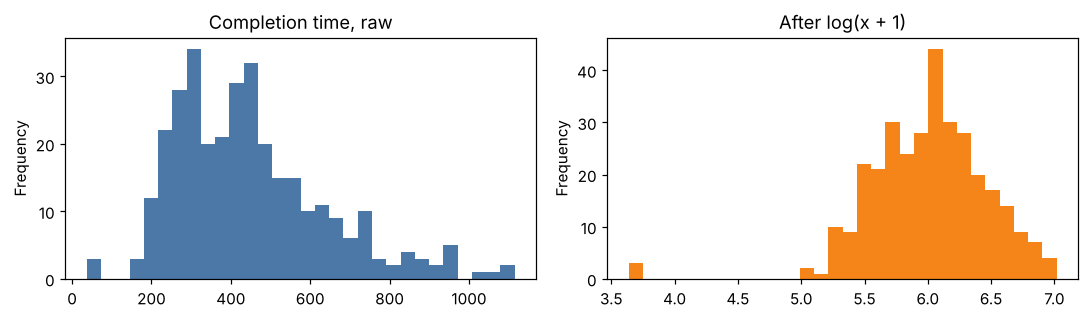

In [55]:
merged["log_duration"] = np.log1p(merged["duration"])
merged["log_pubs"] = np.log1p(merged["pubs"])
print(merged[["duration", "log_duration", "pubs", "log_pubs"]].skew().round(2))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
merged["duration"].plot.hist(bins=30, ax=ax[0], color="#4C78A8", title="Completion time, raw")
merged["log_duration"].plot.hist(bins=30, ax=ax[1], color="#F58518", title="After log(x + 1)")
plt.tight_layout(); plt.show()

<details><summary><b>R equivalent (as on the slide)</b></summary>

```r
log1p(raw$duration)
```
</details>

## 24. Reproduce and report: flow, log and clean file (slides 38–39)

Recommended project layout:

```
fwes-project/
├── data/
│   ├── raw/      read-only
│   └── clean/
├── scripts/      01_import, 02_screen, 03_missing, 04_prepare
├── output/
├── cleaning_log.csv
└── renv.lock / requirements.txt
```

In [56]:
flow = pd.DataFrame([
    ("Responses received", N_RECEIVED, None),
    ("After duplicates", N_AFTER_DUP, f"Excluded {N_RECEIVED - N_AFTER_DUP}: duplicate submissions"),
    ("After attention check", N_AFTER_ATT, f"Excluded {N_AFTER_DUP - N_AFTER_ATT}: failed the instructed-response item"),
    ("After careless responding", N_AFTER_CARELESS, f"Excluded {N_AFTER_ATT - N_AFTER_CARELESS}: long-string and under 2 s per item"),
    ("Analysed sample", N_FINAL, f"Excluded {N_AFTER_CARELESS - N_FINAL}: multivariate outliers, after review"),
], columns=["stage", "N", "exclusion"])
flow

,stage,N,exclusion
0,Responses received,350,NaN
1,After duplicates,344,Excluded 6: duplicate submissions
2,After attention check,335,Excluded 9: failed the instructed-response item
3,After careless responding,328,Excluded 7: long-string and under 2 s per item
4,Analysed sample,323,"Excluded 5: multivariate outliers, after review"


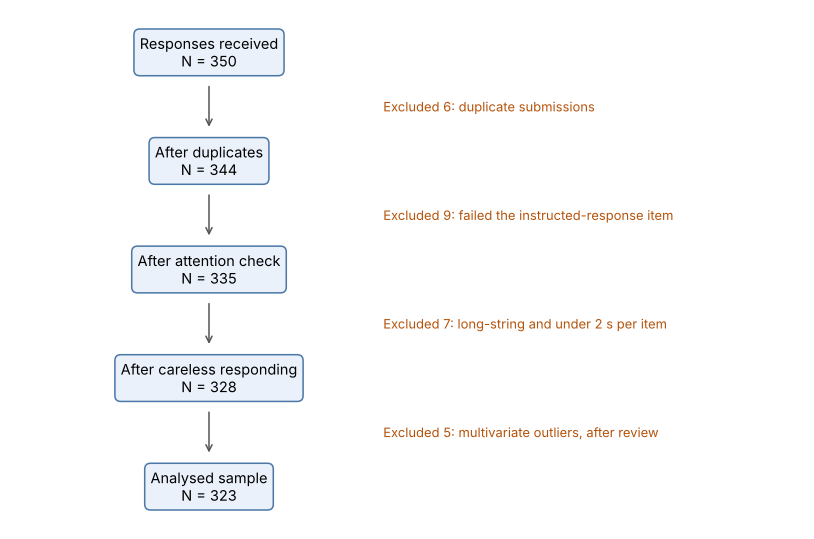

In [57]:
fig, ax = plt.subplots(figsize=(7.5, 5)); ax.axis("off"); ax.set_ylim(0, 1); ax.set_xlim(0, 1)
ys = np.linspace(.92, .08, len(flow))
for k, (y, (_, row)) in enumerate(zip(ys, flow.iterrows())):
    ax.text(.25, y, f"{row['stage']}\nN = {row['N']}", ha="center", va="center", fontsize=9.5,
            bbox=dict(boxstyle="round,pad=.4", fc="#EAF1FB", ec="#4C78A8"))
    if k > 0:
        ax.annotate("", xy=(.25, y + .06), xytext=(.25, ys[k - 1] - .06),
                    arrowprops=dict(arrowstyle="->", color="#555"))
        ax.text(.47, (y + ys[k - 1]) / 2, row["exclusion"], fontsize=8.5, va="center", color="#B5530B")
plt.tight_layout(); plt.show()

In [58]:
log_df = pd.DataFrame(log)
log_df.to_csv("cleaning_log.csv", index=False)
log_df

,step,rule,n_affected,n_remaining,decision
0,Import,"Missing codes '', 'NA', '-' at import; 99 reco...",66,350,Set to missing
1,Range/code,gender 'female'/'f' -> 'F',6,350,Recoded
2,Range/code,desig 'Asst. Prof' -> 'AP',2,350,Recoded
3,Range/code,age outside 22-70,4,350,Set to missing
4,Range/code,Likert item outside 1-5,6,350,Set to missing
5,Consistency,exp_yrs > age - 20,3,350,exp_yrs set to missing
6,Duplicates,Same id (keep earliest) or identical answers u...,6,344,Excluded
7,Careless,Failed instructed-response item (att_chk != 4),9,335,Excluded
8,Careless,Long-string >= 12 AND under 2 s per item,7,328,Excluded
9,Outliers,"Mahalanobis D2 > chi2(4) = 18.47, p < .001 (re...",5,323,Excluded; results compared with and without


In [59]:
keep = (["id", "age", "gender", "desig", "exp_yrs"] + list(raw.loc[:, "jr1":"is6"].columns)
        + ["bo2_r", "bo5_r", "jr", "we", "bo", "is", "att_chk", "duration", "submitted"])
clean = raw[keep].sort_values("id")
clean.to_csv("fwes_clean.csv", index=False)
print("Saved fwes_clean.csv:", clean.shape, "(missing values kept for FIML)")

Saved fwes_clean.csv: (323, 38) (missing values kept for FIML)


## 25. Writing it up in the methods section (slide 40)

The paragraph below is filled in from the numbers computed above, so it always matches the code.

In [60]:
it_final = clean.loc[:, "jr1":"is6"]
miss_pct = it_final.isna().mean() * 100
chi2_f, df_f, p_f = little_mcar(it_final)
sk_f = it_final.agg(["skew", "kurt"]).T
mard = mardia(it_final.dropna())

w = lambda n: ["no", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"][n] if n <= 10 else str(n)
W = lambda n: w(n).capitalize()
text = (
 f"Of the {N_RECEIVED} questionnaires received, {w(N_RECEIVED - N_AFTER_DUP)} duplicate submissions and "
 f"{w(N_AFTER_DUP - N_AFTER_ATT)} respondents who failed the instructed-response item were removed. "
 f"{W(N_AFTER_ATT - N_AFTER_CARELESS)} further cases were excluded because a run of 12 or more identical answers "
 f"was combined with a completion time under two seconds per item. Item-level missingness ranged from "
 f"{miss_pct.min():.1f}% to {miss_pct.max():.1f}%; Little's MCAR test was "
 f"{'not ' if p_f >= .05 else ''}significant (χ² = {chi2_f:.1f}, df = {df_f}, p = {p_f:.2f}), and missing values "
 f"were handled with full information maximum likelihood. {W(N_AFTER_CARELESS - N_FINAL)} cases exceeded the "
 f"Mahalanobis criterion (χ²(4) = {cut:.2f}, p < .001); results with and without them were substantively the same, "
 f"and they were excluded. Skewness ranged from {sk_f['skew'].min():.2f} to {sk_f['skew'].max():.2f} and kurtosis "
 f"from {sk_f['kurt'].min():.2f} to {sk_f['kurt'].max():.2f}; one item (bo4) exceeded ±2 and ±7, and Mardia's test "
 f"indicated multivariate non-normality (kurtosis z = {mard['z']:.2f}, p {'< .001' if mard['p_kurt'] < .001 else '= ' + format(mard['p_kurt'], '.3f')}), "
 f"so models were estimated with robust maximum likelihood (MLR). The final sample comprised {N_FINAL} respondents."
)
print(text)

Of the 350 questionnaires received, six duplicate submissions and nine respondents who failed the instructed-response item were removed. Seven further cases were excluded because a run of 12 or more identical answers was combined with a completion time under two seconds per item. Item-level missingness ranged from 0.3% to 3.1%; Little's MCAR test was not significant (χ² = 988.2, df = 968, p = 0.32), and missing values were handled with full information maximum likelihood. Five cases exceeded the Mahalanobis criterion (χ²(4) = 18.47, p < .001); results with and without them were substantively the same, and they were excluded. Skewness ranged from -0.82 to 2.72 and kurtosis from -0.93 to 7.47; one item (bo4) exceeded ±2 and ±7, and Mardia's test indicated multivariate non-normality (kurtosis z = 6.60, p < .001), so models were estimated with robust maximum likelihood (MLR). The final sample comprised 323 respondents.


Also state: the software and package versions (next cell).

## 26. Final quiz (slide 43)

In [61]:
print("Q1  Reverse-coded value of 2 on a 1-5 item:", (5 + 1) - 2)
print(f"Q2  Mahalanobis cut-off, six composites, p < .001: chi2(6) = {stats.chi2.ppf(.999, 6):.2f}  (df = variables, not N)")
print('Q3  8% missing, MAR plausible, CFA in lavaan: FIML (missing = "fiml"), or MI')

Q1  Reverse-coded value of 2 on a 1-5 item: 4
Q2  Mahalanobis cut-off, six composites, p < .001: chi2(6) = 22.46  (df = variables, not N)
Q3  8% missing, MAR plausible, CFA in lavaan: FIML (missing = "fiml"), or MI


## 27. Software versions (for the methods section and `requirements.txt`)

In [62]:
import sys, sklearn, scipy, matplotlib, statsmodels, missingno, pingouin, factor_analyzer
print("Python", sys.version.split()[0])
for mod in [pd, np, scipy, sklearn, statsmodels, matplotlib, missingno, pingouin]:
    print(f"{mod.__name__:<12} {mod.__version__}")
from importlib.metadata import version
print(f"{'factor_analyzer':<12} {version('factor_analyzer')}")
print(f"{'pyampute':<12} {version('pyampute')}")

Python 3.13.18
pandas       3.0.5
numpy        2.5.3
scipy        1.18.1
sklearn      1.9.1
statsmodels  0.15.0
matplotlib   3.11.2
missingno    0.5.2
pingouin     0.7.0
factor_analyzer 0.5.1
pyampute     0.0.3


<details><summary><b>R equivalent</b></summary>

```r
sessionInfo()
renv::snapshot()
```
</details>

---
**Further reading:** Tabachnick and Fidell (2019), ch. 4 · Hair et al. (2019), ch. 2 · van Buuren (2018), *Flexible Imputation of Missing Data* · Wickham et al. (2023), *R for Data Science* · McKinney (2022), *Python for Data Analysis* · Meade and Craig (2012) · Curran (2016) · Podsakoff et al. (2003) · Kock (2015) · Aguinis, Gottfredson and Joo (2013).